# ANÁLISIS EXPLORATORIO DE DATOS SOBRE LAS TENDENCIAS CINEMATOGRÁFICAS MUNDIALES (2010–2025)
## Desarrollo - Fases 1 Ecosistema

---

### **INFORMACIÓN GENERAL Y METADATOS ACADÉMICOS**
- **Asignatura:** Programación para la Ciencia de Datos
- **Profesor: Omar Salinas Silva** 
- **Fecha de Entrega:** Domingo 8 de Noviembre de 2026
- **Integrantes del Grupo 4:**
  1. Daniela Baeza Rocha
  2. Juan González Elgueta
  3. Elías Manríquez Armijo
  4. Yestxander Rada Gutierrez

---

## 1: COMPRENSIÓN DEL NEGOCIO (BUSINESS UNDERSTANDING)

### 1.1 Contexto de la Industria Cinematográfica Mundial (2010–2025)
Durante el período comprendido entre 2010 y 2025, la industria del cine ha experimentado transformaciones estructurales impulsadas por la digitalización, la masificación de las plataformas de streaming, las variaciones en las preferencias de los espectadores y los cambios macroeconómicos globales. Comprender los factores determinantes de la rentabilidad y popularidad de las producciones cinematográficas es fundamental para la toma de decisiones estratégicas en producción, distribución y marketing.

### 1.2 Formulación del Problema de Investigación
**Pregunta Central:** Análisis exploratorio de datos (AED) sobre las tendencias cinematográficas mundiales durante un período de 15 años (2010-2025).

### 1.3 Objetivos del Estudio
- **Objetivo General:** Desarrollar un Análisis Exploratorio de Datos  sobre un conjunto de datos de 17,978 películas de The Movie Database (TMDB) comprendidas entre 2010 y 2025.


## 2: COMPRENSIÓN DE LOS DATOS (DATA UNDERSTANDING)

### 2.1 Carga del Entorno y Librerías

In [74]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch

# Configuración de estilo visual
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
print("Librerías cargadas exitosamente.")

Librerías cargadas exitosamente.


### 2.2 Carga Inicial del Dataset TMDB

In [75]:
np.random.seed(42)  # semilla para reproducibilidad

rutas_posibles = [
    Path("../data/raw/movies_raw.csv")
]

ruta = next((p for p in rutas_posibles if p.exists()), None)

if ruta is None:
    try:
        from google.colab import files
        cargados = files.upload()
        nombre_archivo = next(iter(cargados))
        ruta = Path(nombre_archivo)
    except Exception as e:
        raise FileNotFoundError(
            "No se encontró BaseFinal.csv. Súbelo al entorno de ejecución."
        ) from e

df = pd.read_csv(ruta)

print(f"Archivo cargado: {ruta}")
print(f"Filas: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]:,}")

Archivo cargado: ..\data\raw\movies_raw.csv
Filas: 17,978
Columnas: 16


#### 2.2.1 Inspección Inicial Dataset TMDB

In [ ]:
# Dimensiones del conjunto de datos


Dimensiones del conjunto de datos: (17978, 16)


In [ ]:
# Muestra Aleaoria de 5 filas del DataFrame


Muestra aleatoria de 5 filas del DataFrame:


,movie_id,title,release_date,status,budget,revenue,runtime,genres,production_companies,production_countries,spoken_languages,original_language,vote_average,vote_count,popularity,adult
5954,10317,Our Brand Is Crisis,2015-09-11,Released,28000000,7002261,107,Comedy|Drama,Participant|Smokehouse Pictures,United States of America,English,en,5.871,533,1.9643,False
2616,149893,Two Lives,2012-10-19,Released,0,1649260,97,Drama|Thriller,Helgeland Film|Zinnober Film- und Fernsehprodu...,Germany|Norway,Deutsch|Norsk,de,6.574,74,0.8469,False
4518,277594,Hercules Reborn,2014-07-08,Released,0,0,90,Adventure|Action,The Asylum,United States of America,English,en,4.216,74,0.4225,False
4400,343750,Dollface,2014-05-28,Released,0,0,95,Horror,Horse Creek Productions,United States of America,English,en,5.491,57,0.3668,False
11789,630027,Fragtime,2019-11-22,Released,0,0,61,Animation|Romance|Science Fiction|Comedy,Tear Studio|Pony Canyon|Akita Shoten|Sotsu|WOW...,Japan,日本語,ja,6.118,51,0.8834,False


Aqui interpretacion de la salida

In [ ]:
# Información general del DataFrame
   

Información general del DataFrame:
<class 'pandas.DataFrame'>
RangeIndex: 17978 entries, 0 to 17977
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   movie_id              17978 non-null  int64  
 1   title                 17978 non-null  str    
 2   release_date          17978 non-null  str    
 3   status                17978 non-null  str    
 4   budget                17978 non-null  int64  
 5   revenue               17978 non-null  int64  
 6   runtime               17978 non-null  int64  
 7   genres                17968 non-null  str    
 8   production_companies  17484 non-null  str    
 9   production_countries  17802 non-null  str    
 10  spoken_languages      17886 non-null  str    
 11  original_language     17978 non-null  str    
 12  vote_average          17978 non-null  float64
 13  vote_count            17978 non-null  int64  
 14  popularity            17978 non-null  float64


Aqui interpretación de la salida

#### 2.2.2 Tipos de variables (Diccionario de datos)

,tipo,n_unicos,faltantes,faltantes_%,ejemplos
movie_id,int64,17978,0,0.00,"[113727, 67250, 43615, 38883]"
title,str,17322,0,0.00,"[Dark Seduction, 12, Lula, the Son of Brazil, ..."
release_date,str,4582,0,0.00,"[2010-01-01, 2010-01-03, 2010-01-04, 2010-01-05]"
status,str,1,0,0.00,[Released]
budget,int64,1091,0,0.00,"[0, 9500000, 20000000, 2000000]"
revenue,int64,6443,0,0.00,"[0, 3785593, 3807808, 22039646]"
runtime,int64,217,0,0.00,"[89, 3, 130, 90]"
genres,str,2857,10,0.06,"[Drama|Thriller|Romance, Comedy, Drama|History..."
production_companies,str,15387,494,2.75,"[Lionsgate, LC Barreto|Filmes do Equador|Inter..."
production_countries,str,1808,176,0.98,"[Mexico, United States of America, Brazil, Fra..."


#### 2.2.3 Estadisticas Dataset TMDB


=== Estadísticas descriptivas ===


,movie_id,title,release_date,status,budget,revenue,runtime,genres,production_companies,production_countries,spoken_languages,original_language,vote_average,vote_count,popularity,adult
count,17978.00,17978,17978,17978,1.797800e+04,1.797800e+04,17978.00,17968,17484,17802,17886,17978,17978.00,17978.00,17978.00,17978
unique,NaN,17322,4582,1,NaN,NaN,NaN,2857,15387,1808,1505,80,NaN,NaN,NaN,1
top,NaN,Return,2020-10-02,Released,NaN,NaN,NaN,Drama,The Asylum,United States of America,English,en,NaN,NaN,NaN,False
freq,NaN,9,21,17978,NaN,NaN,NaN,1473,68,6076,8270,10615,NaN,NaN,NaN,17978
mean,499968.87,NaN,NaN,NaN,8.389049e+06,2.359657e+07,99.50,NaN,NaN,NaN,NaN,NaN,6.33,740.98,2.07,NaN
std,334180.24,NaN,NaN,NaN,2.863707e+07,1.096575e+08,25.05,NaN,NaN,NaN,NaN,NaN,0.88,2122.98,3.08,NaN
min,189.00,NaN,NaN,NaN,0.000000e+00,0.000000e+00,0.00,NaN,NaN,NaN,NaN,NaN,1.83,50.00,0.01,NaN
25%,253307.75,NaN,NaN,NaN,0.000000e+00,0.000000e+00,90.00,NaN,NaN,NaN,NaN,NaN,5.79,80.00,0.79,NaN
50%,444171.00,NaN,NaN,NaN,0.000000e+00,0.000000e+00,98.00,NaN,NaN,NaN,NaN,NaN,6.38,152.00,1.28,NaN
75%,685586.75,NaN,NaN,NaN,2.300000e+06,1.869959e+06,110.00,NaN,NaN,NaN,NaN,NaN,6.95,427.75,2.16,NaN


Interpretación Aqui

### 2.3 Visualizaciones del Dataset TMDB

In [81]:
# Crear la variable release_year a partir de release_date.
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")
df["release_year"] = df["release_date"].dt.year

# Filtrar período de análisis
df = df[(df["release_year"] >= 2010) & (df["release_year"] <= 2025)]

**Evolución de películas estrenadas por año**

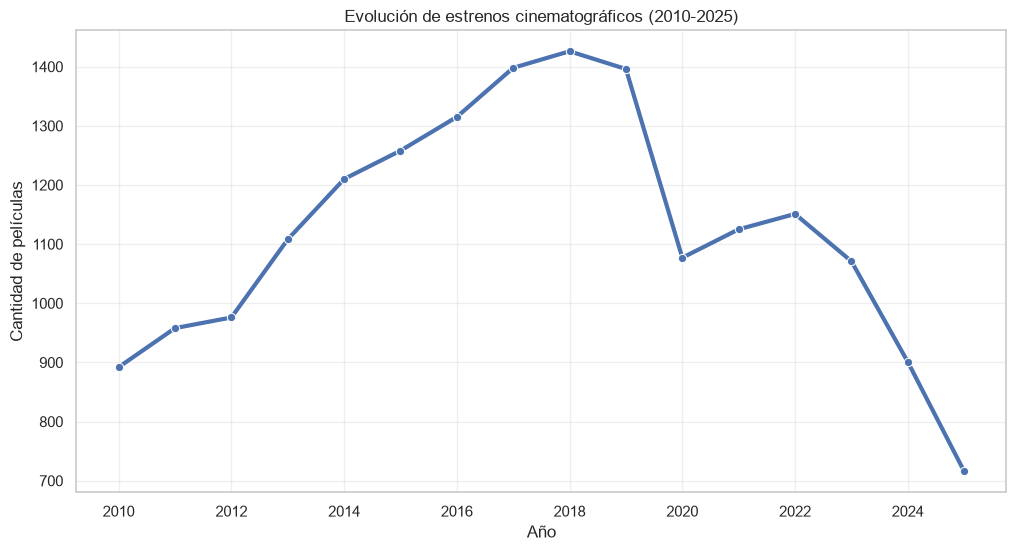

Aqui interpretación salida

**Evolución de la popularidad promedio**

Permite evaluar cómo cambió el interés del público durante el periodo.

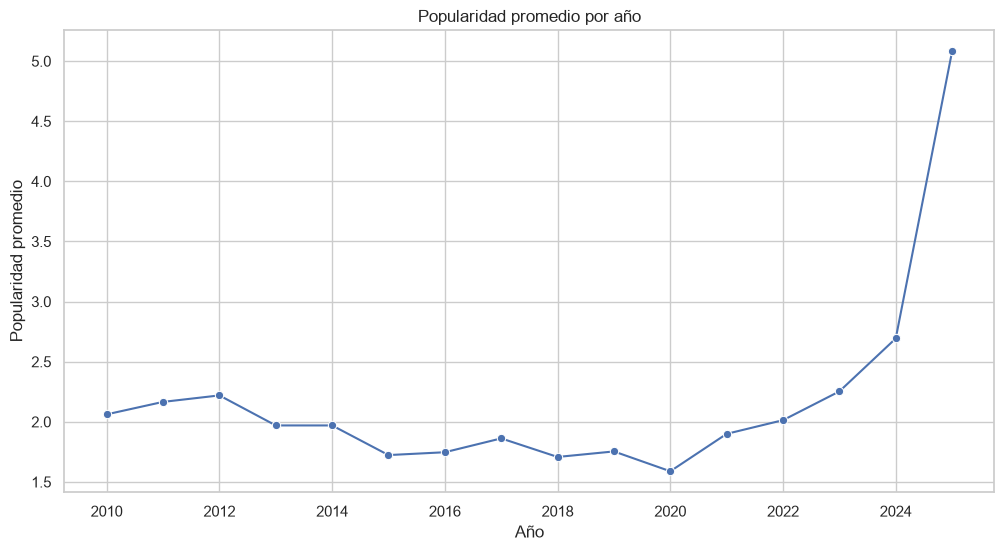

Interpretacion aqui - Puede mostrar períodos donde la industria logró mayor atención global.

**Presupuesto vs Recaudación**

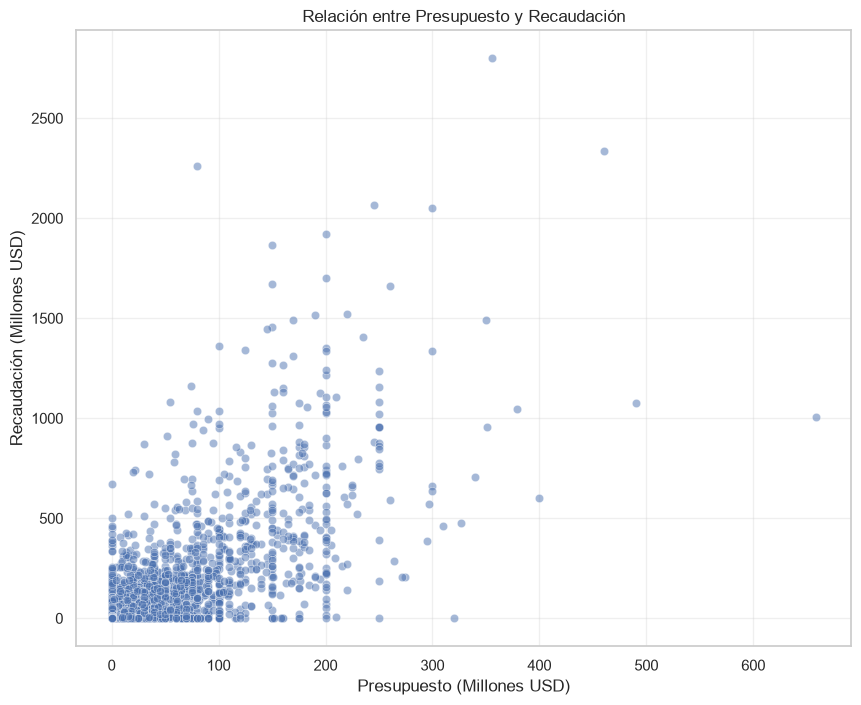

Interpretacion aqui

**Top países productores**

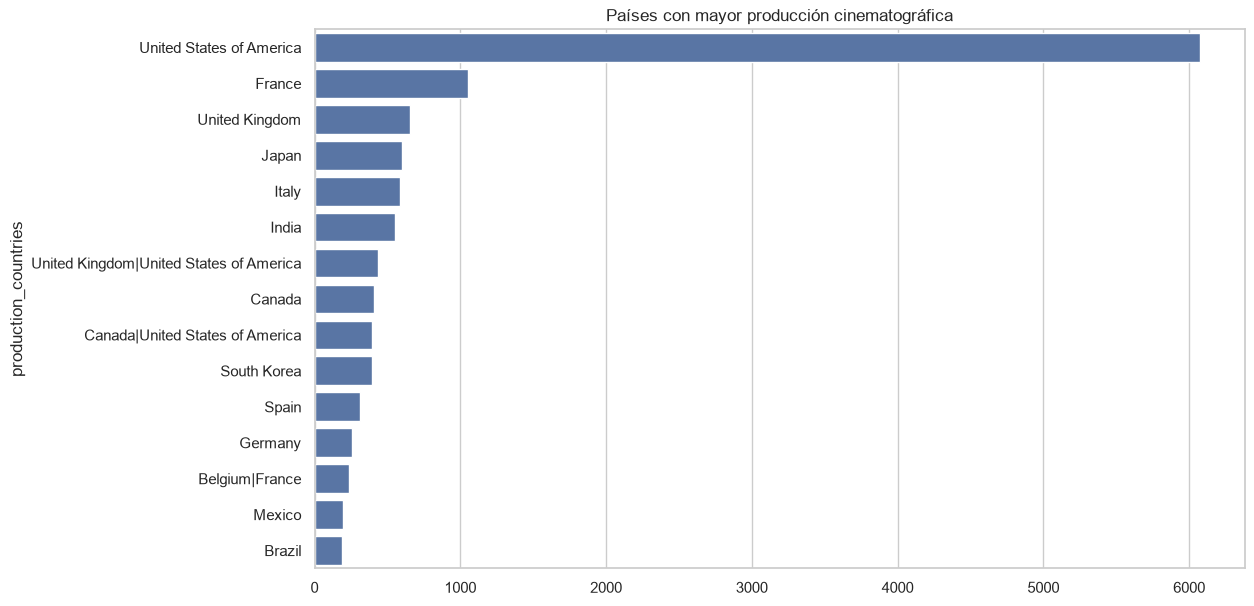